In [15]:
import pandas as pd
from IPython.display import display, Markdown
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import dash
from dash import html, dcc, dash_table
from dash.dependencies import Output, Input, State
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from category_encoders import TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier


df_original = pd.read_csv("data/commercial_planning.csv", encoding="latin-1")

info_df = pd.DataFrame({
    "Tipo de dato": df_original.dtypes,
    "Registros no nulos": df_original.notnull().sum(),
    "Valores faltantes (%)": (df_original.isnull().sum() / len(df_original) * 100).round(2)
})

final_states = ["CLOSED", "COMPLETE", "CANCELED", "SUSPECTED_FRAUD"]
df_original = df_original[df_original["Order Status"].isin(final_states)]
df_original["Order Success"] = df_original["Order Status"].isin(["COMPLETE", "CLOSED"]).astype(int)

display(Markdown("### Estructura y consistencia de los datos"))
display(info_df)
display(Markdown("-" * 70))
display(Markdown(f"#### Variable 'Order Status': {df_original["Order Status"].unique()} ---> Variable Target 'Order Success': {df_original["Order Success"].unique()}"))

### Estructura y consistencia de los datos

,Tipo de dato,Registros no nulos,Valores faltantes (%)
Order Region,object,10401,0.0
Category Name,object,10401,0.0
Shipping Mode,object,10401,0.0
Days for shipment (scheduled),int64,10401,0.0
Order Status,object,10401,0.0
Quantity Items,int64,10401,0.0
Product Price,float64,10401,0.0
Order Discount,float64,10401,0.0


----------------------------------------------------------------------

#### Variable 'Order Status': ['CLOSED' 'COMPLETE' 'CANCELED' 'SUSPECTED_FRAUD'] ---> Variable Target 'Order Success': [1 0]

### El 77.02% de las transacciones terminan en éxito ---> Target Desbalanceada

----------------------------------------------------------------------

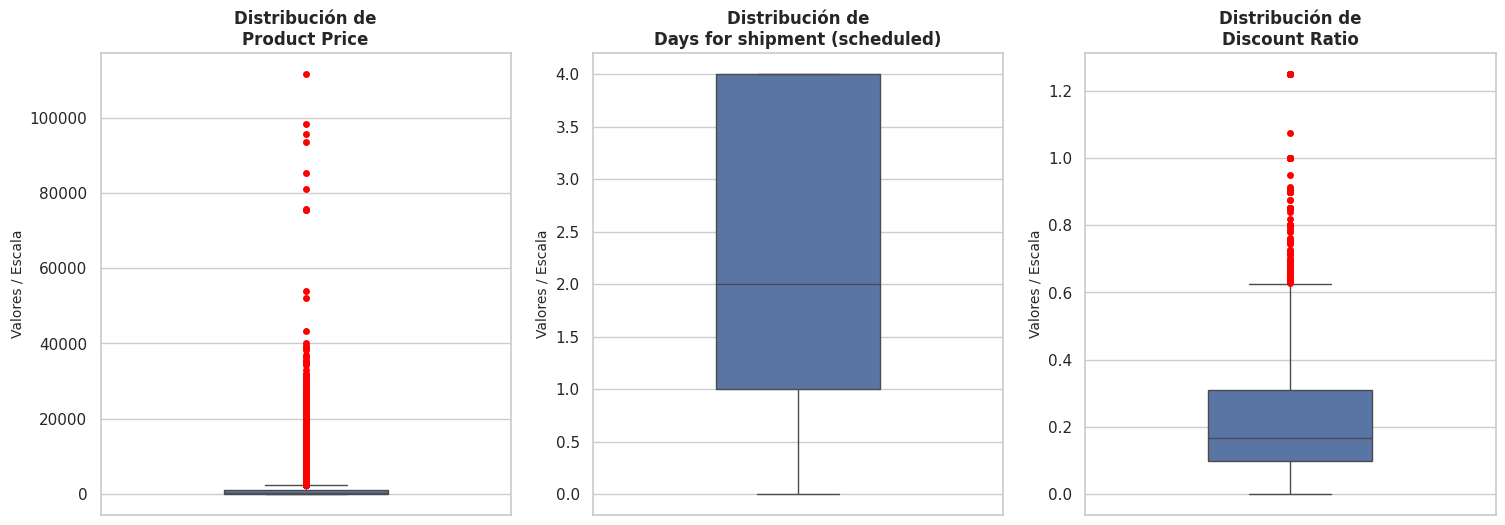

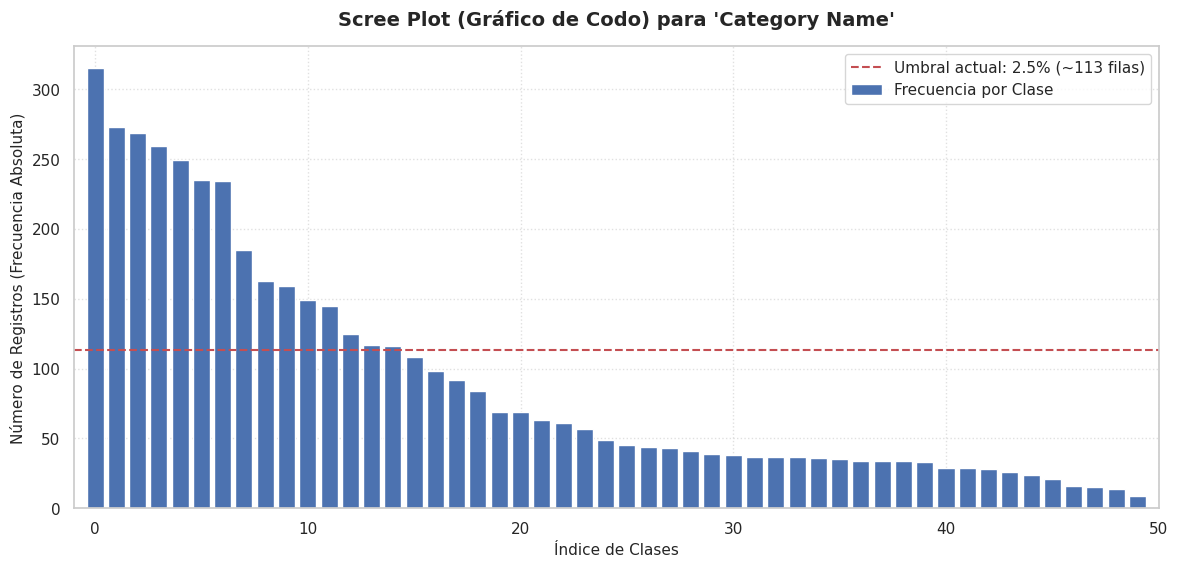

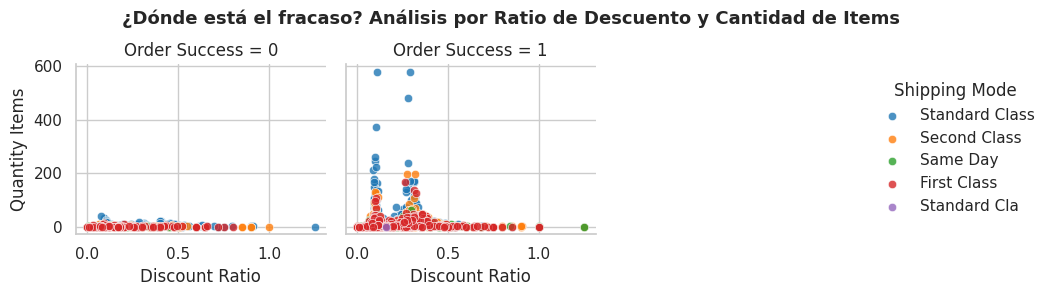

In [16]:
df_original["Discount Ratio"] = df_original["Order Discount"] / df_original["Product Price"]

success_counts = df_original["Order Success"].value_counts(normalize=True) * 100
display(Markdown(f"### El {success_counts[1]:.2f}% de las transacciones terminan en éxito ---> Target Desbalanceada"))
display(Markdown("-" * 70))

numeric_var_limited = ["Discount Ratio"]
numeric_vars = ["Product Price", "Days for shipment (scheduled)"]
categorical_vars = ["Category Name", "Order Region", "Shipping Mode"]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
sns.set_theme(style="whitegrid")

for i, col in enumerate(numeric_vars + numeric_var_limited):
    sns.boxplot(y=df_original[col], ax=axes[i], color="#4C72B0", width=0.4, flierprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "none", "markersize": 5})
    axes[i].set_title(f"Distribución de\n{col}", fontsize=12, fontweight="bold")
    axes[i].set_ylabel("Valores / Escala", fontsize=10)
    axes[i].set_xlabel("")

plt.show()

counts = df_original["Category Name"].value_counts()
percentages = df_original["Category Name"].value_counts(normalize=True)

df_plot = pd.DataFrame({
    "Class": counts.index,
    "Frecuency": counts.values,
    "Percentage": percentages.values
}).reset_index(drop=True)

plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")
plt.bar(df_plot.index, df_plot["Frecuency"], color="b", label="Frecuencia por Clase")

umbral = df_original.shape[0] * 0.025
plt.axhline(y=umbral, color="r", linestyle="--", linewidth=1.5, label=f"Umbral actual: 2.5% (~{int(umbral)} filas)")

plt.title("Scree Plot (Gráfico de Codo) para 'Category Name'", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Índice de Clases", fontsize=11)
plt.ylabel("Número de Registros (Frecuencia Absoluta)", fontsize=11)
plt.xlim(-1, len(df_plot))
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11, loc="upper right")

grid = sns.FacetGrid(df_original.sample(min(2000, len(df_original))), col="Order Success", hue="Shipping Mode", palette="tab10", col_wrap=3)
grid.map(sns.scatterplot, "Discount Ratio", "Quantity Items", alpha=0.8)
grid.add_legend()
grid.fig.subplots_adjust(top=0.8)
grid.fig.suptitle("¿Dónde está el fracaso? Análisis por Ratio de Descuento y Cantidad de Items", fontsize=13, fontweight="bold")
plt.show()

#### Feature Engineering: estandarización con capeo y numeralización target
Este enfoque de preprocesamiento de variables se basa en el Análisis Exploratorio de Datos previo, diseñado para optimizar el rendimiento y la estabilidad del modelo al unificar la escala de los datos y estructurar variables cualitativas. La combinación de estandarización con outliers capeados (percentil = 99) y codificación Target con una reducción previa de multiclases previene el sesgo algorítmico, acelera la convergencia del entrenamiento y garantiza que las métricas de evaluación reflejen la capacidad real de generalización del modelo.


In [17]:
df = df_original.copy()

df.drop(columns=["Order Status","Order Discount"], inplace=True)
df = df.reset_index(drop=True)
df = df[df["Discount Ratio"] <= 1]

def caps_outliers(df, columns):
    caps_high = {}
    for col in columns:
        P99 = df[col].quantile(0.99)
        df[col] = df[col].clip(upper=P99)
        caps_high[col] = P99
    return df, caps_high

df, caps = caps_outliers(df, ["Product Price", "Discount Ratio"])

X = df[categorical_vars + numeric_vars + numeric_var_limited]
y = df["Order Success"]

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=df["Order Success"])

umbral = 0.025
categories_distribution = X_train["Category Name"].value_counts(normalize=True)
valid_categories = categories_distribution[categories_distribution > umbral].index

def group_rare_categories(X, valid_cats=valid_categories):
    X = X.copy()
    X["Category Name"] = X["Category Name"].where(X["Category Name"].isin(valid_cats), "OTHERS")
    return X

rare_grouper = FunctionTransformer(group_rare_categories)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_vars),
        ("cat", TargetEncoder(), categorical_vars)
    ],
    remainder="passthrough"
)

preprocess_pipeline = Pipeline([
    ("rare_groups", rare_grouper),
    ("encoding_and_scaling", preprocessor)
])

X_train_processed = preprocess_pipeline.fit_transform(X_train, y_train)
X_test_processed = preprocess_pipeline.transform(X_test)

feature_names = numeric_vars + categorical_vars + numeric_var_limited

X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

display(Markdown("### DataFrame procesado (análisis predictivo)"))
display(X_train_processed)

### DataFrame procesado (análisis predictivo)

,Product Price,Days for shipment (scheduled),Category Name,Order Region,Shipping Mode,Discount Ratio
4305,-0.292446,-0.109421,0.859636,0.719723,0.817059,0.130006
1034,-0.395547,-0.776299,0.859636,0.750000,0.775395,0.054916
944,-0.329581,-0.109421,0.679245,0.731544,0.817059,0.160012
3502,-0.239401,-0.776299,0.743455,0.718310,0.775395,0.075005
2792,0.325541,1.224334,0.679245,0.720001,0.696262,0.107151
...,...,...,...,...,...,...
246,2.466039,-0.109421,0.554656,0.736842,0.817059,0.100283
608,-0.315005,1.224334,0.859636,0.709091,0.696262,0.340044
3758,-0.019260,-1.443176,0.679245,0.854535,0.864469,0.055004
3748,-0.385284,-0.109421,0.669174,0.854535,0.817059,0.540016


#### Bagging (K-Neighbors): reforzando los casos más cercanos
Es una de las principales técnicas computacionales de estadística inferencial cuya objetivo se basa en eliminar o reducir lo máximo posible la varianza en los resultados, su método es utilizar la sabiduría de las masas, es decir, reforzar el aprendizaje mediante el criterio de distintos metaestimadores que se encargarán de sacar sus propias conclusiones de respectivos datos seleccionados para luego, dependiendo del problema en cuestión, llegar a una respuesta final a través de la media o moda del conjunto de resultados. La agregación de los resultados cancela la varianza individual de cada modelo, resultando en un modelo de conjunto con un error de varianza significativamente menor.
El resultado principal de este modelo es un scoring de riesgo transaccional, una métrica continua y dinámica que va más allá de la clásica clasificación binaria. En este enfoque, las métricas de validación tradicionales como el accuracy o el F1-score pierden peso en la evaluación de precisión, cediendo el protagonismo a indicadores alineados con el impacto real del negocio

In [22]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)

bagging_knn = BaggingClassifier(estimator=knn_classifier,
                                n_estimators=100,
                                max_samples=0.3,
                                bootstrap=True,
                                random_state=42,
                                n_jobs=1)

bagging_knn.fit(X_train_processed, y_train)

calibrated_model = CalibratedClassifierCV(estimator=bagging_knn, method="sigmoid")
calibrated_model.fit(X_test_processed, y_test)
joblib.dump(calibrated_model, "model/bagging_knn_socring.pkl")

prob_risk = calibrated_model.predict_proba(X_test_processed)[:,0]
y_fail = 1 - y_test.values

brier_score = brier_score_loss(y_test, prob_risk, pos_label=0)

df_test = pd.DataFrame({
    "risk_score": prob_risk,
    "target_fail": y_fail
})

df_test["bucket_risk"] = pd.qcut(df_test["risk_score"], 3, duplicates="drop")

risk_table = df_test.groupby("bucket_risk", observed=True).agg(
    real_fail_rate=("target_fail","mean"),
    risk_score_mean=("risk_score","mean"),
    obs_quantity=("risk_score","count")
).reset_index().sort_values("risk_score_mean", ascending=False)

risk_table["bucket_risk"] = risk_table["bucket_risk"].astype(str)

df_high_risk = df_original.loc[(df_original["Order Region"] == "South America") &
                              (df_original["Shipping Mode"] == "Standard Class") &
                              (df_original["Discount Ratio"] < 0.5),:].copy()

new_object = df_high_risk.sample(n=1)
new_object.drop(columns=["Order Status","Order Discount"], inplace=True)
new_object = new_object.reset_index(drop=True)

object_processed = preprocess_pipeline.transform(new_object)

predict_proba = bagging_knn.predict_proba(object_processed)
prob_fail = predict_proba[0,0] * 100

if prob_fail <= 25.0:
    level_risk = "Tolerable"
elif 25.0 < prob_fail <= 40.0:
    level_risk = "Importante"
else:
    level_risk = "Intolerable"


display(Markdown("#### --- RESULTADOS DE VALIDACION DEL MODELO ---"))
display(risk_table)
print("-"*100)
print(f"Interpretación: Calibración validada con un Error Absoluto Medio inferior al 5% y un Brier Score de {brier_score:.2f}.")
if brier_score < 0.12:
    print("Estado: MODELADO VÁLIDO PARA PRODUCCIÓN (APROBADO) - Probailidades calibradas y estables para scoring")
display(Markdown("-"*70))
display(Markdown("#### Nueva planificación comercial (ejemplo)"))
print("-"*50)
display(Markdown(f"#### Riesgo de fracaso: {prob_fail:.2f}% ({level_risk})"))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


#### --- RESULTADOS DE VALIDACION DEL MODELO ---

,bucket_risk,real_fail_rate,risk_score_mean,obs_quantity
2,"(0.214, 0.944]",0.544850,0.497352,301
1,"(0.0955, 0.214]",0.126667,0.138408,300
0,"(0.0418, 0.0955]",0.016611,0.063815,301


----------------------------------------------------------------------------------------------------
Interpretación: Calibración validada con un Error Absoluto Medio inferior al 5% y un Brier Score de 0.11.
Estado: MODELADO VÁLIDO PARA PRODUCCIÓN (APROBADO) - Probailidades calibradas y estables para scoring


----------------------------------------------------------------------

#### Nueva planificación comercial (ejemplo)

--------------------------------------------------


#### Riesgo de fracaso: 7.20% (Tolerable)

#### Herramienta interactiva basada en un socring de riesgo en la ejecución de nuevas planficaciones comerciales

In [ ]:
X_pca = X_train[numeric_vars + numeric_var_limited]
pca = PCA(n_components=2)
pca_results = pca.fit_transform(X_pca)
df_pca = pd.DataFrame(pca_results, columns=["PC1", "PC2"])
df_pca["Order Success"] = y_train.values

success = df_pca.loc[df_pca["Order Success"] == 1,:]
fails = df_pca.loc[df_pca["Order Success"] == 0,:]

prc = df["Order Success"].value_counts(normalize=True)
success_prc = round(prc.get(1, 0) * 100, 1)
fails_prc = round(prc.get(0, 0) * 100, 1)

probability_text = html.B(id="probability", children=[], style={})

fig_pca = go.Figure()
fig_pca.add_trace(go.Scatter(x=success["PC1"], y=success["PC2"], mode="markers", marker_color="green", name=f"Completadas ({success_prc}%)"))
fig_pca.add_trace(go.Scatter(x=fails["PC1"], y=fails["PC2"], mode="markers", marker_color="red", name=f"Sin Éxito ({fails_prc}%)"))
fig_pca.update_layout(title="Resultados de Operaciones Históricas")
fig_pca.update_layout(legend=dict(font=dict(size=9)))

app = dash.Dash(__name__)
server = app.server

app.layout =  html.Div(id="body",className="e4_body",children=[
    html.H1("Evaluación de riesgo en planificaciones comerciales",id="title",className="e4_title"),
    html.Div(id="dashboard", className="e4_dashboard", children=[
        html.Div(id="graph_div", className="e4_graph_div", children=[
            dcc.Graph(id="graph_pca", className="e4_graph", figure=fig_pca),
            html.Div(id="table_div", className="e4_graph", children=[
                dash_table.DataTable(id="table",
                      columns=[
                          {"name": "Días de envío (programado)", "id": "Days for shipment (scheduled)"},
                          {"name": "Región", "id": "Order Region"},
                          {"name": "Categoría", "id": "Category Name"},
                          {"name": "Precio del producto", "id": "Product Price"},
                          {"name": "Tasa de descuento", "id": "Discount Ratio"},
                          {"name": "Tipo de envío", "id": "Shipping Mode"},
                          {"name": "Riesgo de fracaso", "id": "Fail Risk"}
                      ],
                      data=[],
                      fill_width=True,
                      style_table={"width":"100%","minWidth":"100%","maxHeight":"100%"},
                      style_cell={"textAlign":"left","padding":"5px","fontFamily":"Arial","fontSize":"12px","whiteSpace":"normal","height":"auto"},
                      style_header={"backgroundColor":"#f4f4f4","fontWeight":"bold"})])
        ]),
        html.Div(id="input_div", style={"display":"flex","flexWrap":"wrap","gap":"10px"}, children=[
            dcc.Input(id="input_1", type="number", placeholder="Días envío", style={"width":"75px"}),
            dcc.Input(id="input_4", type="number", placeholder="Precio Producto", style={"width":"75px"}),
            dcc.Input(id="input_5", type="number", placeholder="Ratio Descuento", style={"width":"75px"}),
            dcc.Dropdown(id="input_2", options=[{"label": i, "value": i} for i in df["Order Region"].unique()], placeholder="Región", style={"width":"150px"}),
            dcc.Dropdown(id="input_3", options=[{"label": i, "value": i} for i in X_train["Category Name"].unique()], placeholder="Categoría", style={"width":"150px"}),
            dcc.Dropdown(id="input_6", options=[{"label": i, "value": i} for i in df["Shipping Mode"].unique()], placeholder="Tipo Envío", style={"width":"150px"}),
            html.Button(id="button", className="e4_button", children="Enviar", n_clicks=0)
        ]),
        html.P(["predicción: riesgo de fracaso del ",probability_text],className="e4_predict")
    ])
])


@app.callback(
    [Output(component_id="graph_pca",component_property="figure"),
    Output(component_id="probability",component_property="children"),
    Output(component_id="probability",component_property="style"),
    Output(component_id="table", component_property="data")],
    [Input(component_id="button",component_property="n_clicks")],
    [State(component_id="input_1",component_property="value"),
    State(component_id="input_2",component_property="value"),
    State(component_id="input_3",component_property="value"),
    State(component_id="input_4",component_property="value"),
    State(component_id="input_5",component_property="value"),
    State(component_id="input_6",component_property="value"),
    State(component_id="table", component_property="data")]
)

def get_risk_prob(n_clicks, var_1, var_2, var_3, var_4, var_5, var_6, table_data):

    fig_update = go.Figure(fig_pca)
    prob_fail_text = "0.00%"
    style_res = {"color": "black"}

    inputs = [var_1, var_2, var_3, var_4, var_5, var_6, var_7]
    if n_clicks > 0 and all(v is not None for v in inputs):
        new_object = pd.DataFrame({
            "Days for shipment (scheduled)": [float(var_1)],
            "Order Region": [str(var_2)],
            "Category Name": [str(var_3)],
            "Product Price": [float(var_4)],
            "Discount Ratio": [float(var_5)],
            "Shipping Mode": [str(var_6)]
        })

        object_processed = preprocess_pipeline.transform(new_object)
        object_processed = pd.DataFrame(object_processed, columns=feature_names)
        obj_pca = pca.transform(object_processed[numeric_vars + numeric_var_limited])

        prob_fail = calibrated_model.predict_proba(object_processed)[0,0] * 100
        prob_fail_text = f"{prob_fail:.2f}%"

        if prob_fail <= 25:
            factor = prob_fail / 25
            hue = int(120 - (factor * 60))
            color_res = f"hsl({hue}, 100%, 50%)"
        elif 25 < prob_fail <= 50:
            factor = (prob_fail - 25) / 25
            hue = int(60 - (factor * 60))
            color_res = f"hsl({hue}, 100%, 50%)"
        elif 50 < prob_fail <= 75:
            factor = (prob_fail - 50) / 25
            lightness = int(50 - (factor * 15))
            color_res = f"hsl(0, 100%, {lightness}%)"
        else:
            factor = (prob_fail - 75) / 25
            lightness = int(35 - (factor * 20))
            color_res = f"hsl(0, 100%, {lightness}%)"

        style_res = {"color":color_res}

        fig_update.add_trace(go.Scatter(
            x=[obj_pca[0, 0]],
            y=[obj_pca[0, 1]],
            mode="markers",
            marker=dict(color="blueviolet", size=12, symbol="star"),
            name=f"Nueva Operación {n_clicks}"
        ))

        new_row = {
            "Days for shipment (scheduled)": var_1,
            "Region": var_2,
            "Category": var_3,
            "Product Price ": var_4,
            "Discount Ratio": var_5,
            "Shipping Mode": var_6,
            "Fail Risk": prob_fail_text
        }

        table_data.append(new_row)

    return fig_update, prob_fail_text, style_res, table_data


if __name__ == "__main__":
    app.run(debug=False)